# Mount Drive & chọn GPU

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!nvidia-smi   # kiểm tra A100

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Sat Oct 10 15:35:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   29C    P0             47W /  400W |       0MiB /  40960MiB |      0%      Default |
|          

# Giải nén dataset

In [ ]:
DRIVE_ZIP_PATH = "/content/drive/MyDrive/Datasets/CAERS_train.zip"

!mkdir -p /content/CAER-S
!unzip -q "$DRIVE_ZIP_PATH" -d /content/CAER-S
!ls /content/CAER-S/train   # phải thấy 7 folder: Angry Disgust Fear Happy Neutral Sad Surprise

Angry  Disgust	Fear  Happy  Neutral  Sad  Surprise


# Clone repo

In [ ]:
!git clone https://github.com/huongng389/Exp-CLIP.git /content/Exp-CLIP
%cd /content/Exp-CLIP

Cloning into '/content/Exp-CLIP'...
remote: Enumerating objects: 349, done.
remote: Counting objects: 100% (349/349), done.
remote: Compressing objects: 100% (95/95), done.
remote: Total 349 (delta 264), reused 336 (delta 252), pack-reused 0 (from 0)
Receiving objects: 100% (349/349), 30.28 MiB | 26.26 MiB/s, done.
Resolving deltas: 100% (264/264), done.
/content/Exp-CLIP


## Pull code

In [ ]:
%cd /content/Exp-CLIP
!git pull

/content/Exp-CLIP
Already up to date.


# Cài dependencies

 Tạo venv Python 3.10

In [ ]:
!sudo apt-get -qq update > /dev/null
!sudo apt-get -qq install -y python3.10 python3.10-venv python3.10-distutils > /dev/null
!python3.10 -m venv /content/venv310
!/content/venv310/bin/pip install -q --upgrade pip

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 7.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 16.6 MB/s eta 0:00:00


In [ ]:
!/content/venv310/bin/python --version

Python 3.10.22


Cài torch (khớp CUDA) + dependencies + lavis vào venv đó

In [ ]:
!sudo apt-get -qq update > /dev/null   # làm mới danh sách gói, tránh lỗi 404 khi deadsnakes đã thay bản mới
!sudo apt-get -qq install -y python3.10 python3.10-venv python3.10-distutils > /dev/null
!python3.10 -m venv /content/venv310
!/content/venv310/bin/pip install -q --upgrade pip

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


# Crop mặt CAER-S bằng RetinaFace
Tác giả crop mặt CAER-S bằng RetinaFace trước khi train (paper: ~45K ảnh mặt).

In [ ]:
# Crop mặt bằng RetinaFace (giữ mặt lớn nhất, bỏ ảnh không có mặt).
# Nếu đã có bản crop trên Drive thì chỉ giải nén, không crop lại.
import os
FACE_ZIP = "/content/drive/MyDrive/Datasets/CAERS_Face_train.zip"

if os.path.exists(FACE_ZIP):
    !mkdir -p /content/CAER-S_Face
    !unzip -q -n "$FACE_ZIP" -d /content/CAER-S_Face
else:
    # chạy lại được nếu bị ngắt: ảnh đã crop sẽ được bỏ qua
    !/content/venv310/bin/python tools/crop_faces.py --src /content/CAER-S/train --dst /content/CAER-S_Face/train

Downloading: "https://github.com/elliottzheng/face-detection/releases/download/0.0.1/Resnet50_Final.pth" to /root/.cache/torch/hub/checkpoints/Resnet50_Final.pth








total=49007 saved=48938 no_face=69 unreadable=0


Kiểm tra kết quả crop

Số ảnh sau khi crop: 48938
  Angry: 6993
  Disgust: 6992
  Fear: 6993
  Happy: 6988
  Neutral: 6996
  Sad: 6987
  Surprise: 6989


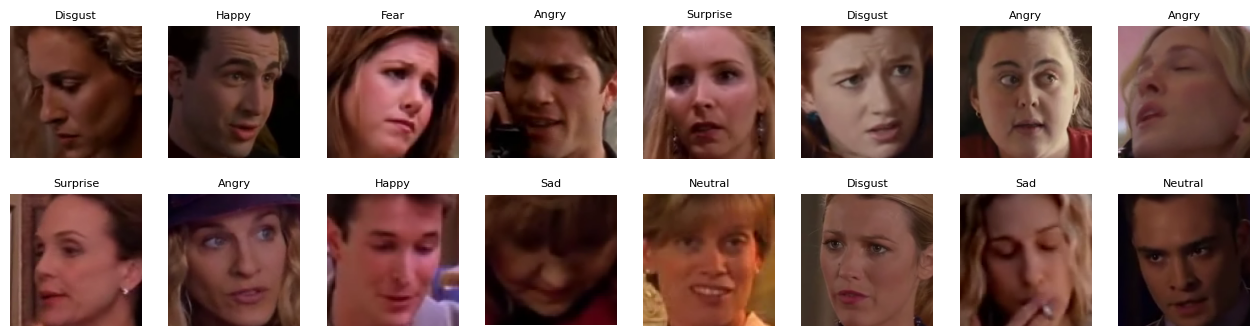

In [17]:
# Đếm số ảnh (paper: ~45K) và xem thử vài ảnh đã crop
import glob, random
import matplotlib.pyplot as plt
from PIL import Image

files = glob.glob("/content/CAER-S_Face/train/*/*")
print("Số ảnh sau khi crop:", len(files))
for d in sorted(glob.glob("/content/CAER-S_Face/train/*")):
    print(f"  {os.path.basename(d)}: {len(os.listdir(d))}")

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for ax, f in zip(axes.flat, random.sample(files, 16)):
    ax.imshow(Image.open(f).convert("RGB"))
    ax.set_title(f.split("/")[-2], fontsize=8)
    ax.axis("off")
plt.show()

Lưu bản crop lên Drive để lần sau không phải crop lại

In [18]:
# Chỉ chạy khi crop đã xong và ảnh trông ổn
if not os.path.exists(FACE_ZIP):
    !cd /content/CAER-S_Face && zip -qr "$FACE_ZIP" train
!ls -lh "$FACE_ZIP"

-rw------- 1 root root 1.4G Oct 10 15:38 /content/drive/MyDrive/Datasets/CAERS_Face_train.zip


In [19]:
!du -sh /content/* 2>/dev/null | sort -rh | head -15
!du -sh /root/.cache/* ~/.cache/* 2>/dev/null | sort -rh | head -15
!du -sh /usr/local/lib/python3.10/dist-packages/* 2>/dev/null | sort -rh | head -15
!du -sh /content/venv310/lib/python3.10/site-packages/* 2>/dev/null | sort -rh | head -15

11G	/content/drive
9.2G	/content/CAER-S
5.9G	/content/venv310
1.6G	/content/CAER-S_Face
69M	/content/Exp-CLIP
55M	/content/sample_data
2.9G	/root/.cache/pip
105M	/root/.cache/torch
56M	/root/.cache/node-gyp
32K	/root/.cache/matplotlib
8.0K	/root/.cache/antigravity
3.9G	/content/venv310/lib/python3.10/site-packages/torch
185M	/content/venv310/lib/python3.10/site-packages/triton
154M	/content/venv310/lib/python3.10/site-packages/pyarrow
119M	/content/venv310/lib/python3.10/site-packages/spacy
116M	/content/venv310/lib/python3.10/site-packages/opencv_python.libs
109M	/content/venv310/lib/python3.10/site-packages/scipy
101M	/content/venv310/lib/python3.10/site-packages/pycocoevalcap
82M	/content/venv310/lib/python3.10/site-packages/cv2
65M	/content/venv310/lib/python3.10/site-packages/pandas
64M	/content/venv310/lib/python3.10/site-packages/cmake
61M	/content/venv310/lib/python3.10/site-packages/opencv_python_headless.libs
60M	/content/venv310/lib/python3.10/site-packages/plotly
57M	/conte

In [ ]:
!nproc

12


# Chạy train (đúng cấu hình runner.sh / paper, backbone L14, 3 seed)
Checkpoint, file resume và log được copy lên `OUT_DIR` sau mỗi epoch.

In [20]:
import os
INSTRUCTION = "Please play the role of a facial action describer. Objectively describe the detailed facial actions of the person in the image."
TRAIN_DATA = "/content/CAER-S_Face/train"
OUT_DIR = "/content/drive/MyDrive/ExpCLIP_output"
T5_CACHE = "/root/.cache/huggingface/hub/models--google--flan-t5-xxl"

def job_id(seed):
    return f"expclip_l14_face_seed{seed}"

## seed 1

In [21]:
SEED = 1
JOB_ID = job_id(SEED)
# nếu FlanT5 đã có trong cache (từ lần train trước trong cùng runtime) thì không gọi HuggingFace nữa
os.environ["HF_HUB_OFFLINE"] = "1" if os.path.isdir(T5_CACHE) else "0"

!/content/venv310/bin/python train.py \
  --workers 8 --epochs 5 --batch-size 512 --batch-size-test-image 512 --batch-size-test-video 64 \
  --lr 1e-3 --weight-decay 1e-4 --momentum 0.9 --print-freq 10 --milestones 30 --seed $SEED \
  --job-id $JOB_ID \
  --instruction "$INSTRUCTION" \
  --load-model "CLIP_L14" \
  --train-data $TRAIN_DATA \
  --extra-checkpoint-dir $OUT_DIR

Training date:  26-10-10 15:39
************************
workers = 8
epochs = 5
batch_size = 512
batch_size_test_image = 512
batch_size_test_video = 64
lr = 0.001
weight_decay = 0.0001
momentum = 0.9
print_freq = 10
milestones = [30]
seed = 1
job_id = expclip_l14_face_seed1
instruction = Please play the role of a facial action describer. Objectively describe the detailed facial actions of the person in the image.
load_model = CLIP_L14
extra_checkpoint_dir = /content/drive/MyDrive/ExpCLIP_output
train_data = /content/CAER-S_Face/train
resume = None
************************

/content/venv310/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(



















********************0********************
Epoch: [0][ 0/95]	Loss 6.5234 (6.5234)	Accuracy  0.391 ( 0.391)
Epoch: 

## seed 2

In [22]:
SEED = 2
JOB_ID = job_id(SEED)
# nếu FlanT5 đã có trong cache (từ lần train trước trong cùng runtime) thì không gọi HuggingFace nữa
os.environ["HF_HUB_OFFLINE"] = "1" if os.path.isdir(T5_CACHE) else "0"

!/content/venv310/bin/python train.py \
  --workers 8 --epochs 5 --batch-size 512 --batch-size-test-image 512 --batch-size-test-video 64 \
  --lr 1e-3 --weight-decay 1e-4 --momentum 0.9 --print-freq 10 --milestones 30 --seed $SEED \
  --job-id $JOB_ID \
  --instruction "$INSTRUCTION" \
  --load-model "CLIP_L14" \
  --train-data $TRAIN_DATA \
  --extra-checkpoint-dir $OUT_DIR

Training date:  26-10-10 16:50
************************
workers = 8
epochs = 5
batch_size = 512
batch_size_test_image = 512
batch_size_test_video = 64
lr = 0.001
weight_decay = 0.0001
momentum = 0.9
print_freq = 10
milestones = [30]
seed = 2
job_id = expclip_l14_face_seed2
instruction = Please play the role of a facial action describer. Objectively describe the detailed facial actions of the person in the image.
load_model = CLIP_L14
extra_checkpoint_dir = /content/drive/MyDrive/ExpCLIP_output
train_data = /content/CAER-S_Face/train
resume = None
************************
/content/venv310/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(

********************0********************
Epoch: [0][ 0/95]	Loss 6.4798 (6.4798)	Accuracy  0.781 ( 0.781)
Epoch: [0][10/95]	Loss 6.3

## seed 3

In [23]:
SEED = 3
JOB_ID = job_id(SEED)
# nếu FlanT5 đã có trong cache (từ lần train trước trong cùng runtime) thì không gọi HuggingFace nữa
os.environ["HF_HUB_OFFLINE"] = "1" if os.path.isdir(T5_CACHE) else "0"

!/content/venv310/bin/python train.py \
  --workers 8 --epochs 5 --batch-size 512 --batch-size-test-image 512 --batch-size-test-video 64 \
  --lr 1e-3 --weight-decay 1e-4 --momentum 0.9 --print-freq 10 --milestones 30 --seed $SEED \
  --job-id $JOB_ID \
  --instruction "$INSTRUCTION" \
  --load-model "CLIP_L14" \
  --train-data $TRAIN_DATA \
  --extra-checkpoint-dir $OUT_DIR

Training date:  26-10-10 17:42
************************
workers = 8
epochs = 5
batch_size = 512
batch_size_test_image = 512
batch_size_test_video = 64
lr = 0.001
weight_decay = 0.0001
momentum = 0.9
print_freq = 10
milestones = [30]
seed = 3
job_id = expclip_l14_face_seed3
instruction = Please play the role of a facial action describer. Objectively describe the detailed facial actions of the person in the image.
load_model = CLIP_L14
extra_checkpoint_dir = /content/drive/MyDrive/ExpCLIP_output
train_data = /content/CAER-S_Face/train
resume = None
************************
/content/venv310/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(

********************0********************
Epoch: [0][ 0/95]	Loss 6.4313 (6.4313)	Accuracy  0.195 ( 0.195)
Epoch: [0][10/95]	Loss 6.3

## Resume (chỉ dùng khi Colab bị ngắt giữa chừng)
Đặt `SEED` đúng seed đang train dở, chạy lại các cell setup phía trên (mount, giải nén, clone, venv, CAER-S_Face, config) rồi chạy cell này.

In [ ]:
# SEED = 2
# JOB_ID = job_id(SEED)
# os.environ["HF_HUB_OFFLINE"] = "1" if os.path.isdir(T5_CACHE) else "0"
# !/content/venv310/bin/python train.py \
#   --workers 8 --epochs 5 --batch-size 512 --batch-size-test-image 512 --batch-size-test-video 64 \
#   --lr 1e-3 --weight-decay 1e-4 --momentum 0.9 --print-freq 10 --milestones 30 --seed $SEED \
#   --job-id $JOB_ID \
#   --instruction "$INSTRUCTION" \
#   --load-model "CLIP_L14" \
#   --train-data $TRAIN_DATA \
#   --extra-checkpoint-dir $OUT_DIR \
#   --resume $OUT_DIR/$JOB_ID-resume.pth

# Xác nhận checkpoint đã lưu trên Drive

In [24]:
!ls -lh "$OUT_DIR"

total 109M
-rw------- 1 root root 3.9K Oct 10 16:28 expclip_l14_face_seed1-log.txt
-rw------- 1 root root  13M Oct 10 16:28 expclip_l14_face_seed1-model.pth
-rw------- 1 root root  25M Oct 10 16:28 expclip_l14_face_seed1-resume.pth
-rw------- 1 root root 3.9K Oct 10 17:37 expclip_l14_face_seed2-log.txt
-rw------- 1 root root  13M Oct 10 17:37 expclip_l14_face_seed2-model.pth
-rw------- 1 root root  25M Oct 10 17:37 expclip_l14_face_seed2-resume.pth
-rw------- 1 root root 3.9K Oct 10 18:29 expclip_l14_face_seed3-log.txt
-rw------- 1 root root  13M Oct 10 18:29 expclip_l14_face_seed3-model.pth
-rw------- 1 root root  25M Oct 10 18:29 expclip_l14_face_seed3-resume.pth
-rw------- 1 root root  41K Aug 19 07:38 expclip_l14_run1-log.png
-rw------- 1 root root 4.6K Aug 19 07:38 expclip_l14_run1-log.txt


# Giải nén test set

In [25]:
!mkdir -p /content/static_test_sets
!unzip -q /content/drive/MyDrive/Datasets/static_test_sets.zip -d /content/static_test_sets
!ls /content/static_test_sets
!ls /content/static_test_sets/RAFDB/test   # phải thấy 0_Happiness ... 6_Fear

AffectNet7  AffectNet8	FERPlus  RAFDB
0_Happiness  1_Sadness	2_Neutral  3_Anger  4_Surprise	5_Disgust  6_Fear


# Chạy test (3 seed)

In [26]:
# Test cả 3 seed; nếu runtime đã reset thì lấy checkpoint từ Drive
!mkdir -p checkpoint log
for SEED in [1, 2, 3]:
    JOB_ID = job_id(SEED)
    if not os.path.exists(f"checkpoint/{JOB_ID}-model.pth"):
        !cp "$OUT_DIR/$JOB_ID-model.pth" checkpoint/
    !/content/venv310/bin/python test.py --load-model "CLIP_L14" --job-id $JOB_ID --data-root /content/static_test_sets 2>&1 | tee log/$JOB_ID-test.txt
    !cp log/$JOB_ID-test.txt "$OUT_DIR/"

************************
load_model = CLIP_L14
job_id = expclip_l14_face_seed1
data_root = /content/static_test_sets
************************
************************************************************************** Zero-shot Prompt Type:  Class Name
******************** Static FER Zero-shot Performance ********************
************************* RAFDB
UAR/WAR: 50.36/56.58
************************* AffectNet7
UAR/WAR: 42.51/42.51
************************* AffectNet8
UAR/WAR: 36.95/36.95
************************* FERPlus
UAR/WAR: 38.27/45.45
************************************************************************** Zero-shot Prompt Type:  An Expression of Name
******************** Static FER Zero-shot Performance ********************
************************* RAFDB
UAR/WAR: 56.73/64.05
************************* AffectNet7
UAR/WAR: 44.00/44.00
************************* AffectNet8
UAR/WAR: 38.33/38.33
************************* FERPlus
UAR/WAR: 39.99/52.92
*****************************

# Trung bình 3 seed

In [27]:
# Trung bình UAR/WAR qua 3 seed (định dạng giống bảng trong paper)
import re
import pandas as pd

rows = []
for SEED in [1, 2, 3]:
    prompt, dataset = None, None
    for line in open(f"log/{job_id(SEED)}-test.txt"):
        if "Prompt Type:" in line:
            prompt = line.split("Prompt Type:")[1].strip()
        elif re.match(r"^\*+ (RAFDB|AffectNet7|AffectNet8|FERPlus)$", line.strip()):
            dataset = line.strip().split()[-1]
        elif line.startswith("UAR/WAR:"):
            uar, war = map(float, line.split(":")[1].strip().split("/"))
            rows.append(dict(seed=SEED, prompt=prompt, dataset=dataset, UAR=uar, WAR=war))

df = pd.DataFrame(rows)
summary = df.groupby(["prompt", "dataset"], sort=False)[["UAR", "WAR"]].agg(["mean", "std"]).round(2)
summary.to_csv(f"{OUT_DIR}/expclip_l14_face_summary.csv")
summary

UAR          WAR  \
                                                          mean   std   mean   
prompt                                       dataset                          
Class Name                                   RAFDB       50.23  0.57  54.56   
                                             AffectNet7  41.47  1.06  41.47   
                                             AffectNet8  35.76  1.20  35.76   
                                             FERPlus     38.58  1.33  45.82   
An Expression of Name                        RAFDB       55.34  1.24  62.00   
                                             AffectNet7  43.79  0.29  43.79   
                                             AffectNet8  38.40  0.34  38.40   
                                             FERPlus     38.89  1.38  51.62   
A Photo of A Face with An Expression of Name RAFDB       55.64  0.96  64.78   
                                             AffectNet7  44.39  0.42  44.39   
                                             AffectNet8  38.08  0.13  38.08   
                                             FERPlus     37.95  1.26  49.17   
Expression Ensemble Five                     RAFDB       58.07  0.72  65.32   
                                             AffectNet7  44.17  0.53  44.17   
                                             AffectNet8  38.84  0.58  38.84   
                                             FERPlus     41.55  1.21  53.41   
Expression Ensemble Ten                      RAFDB       57.19  0.54  64.60   
                                             AffectNet7  44.97  0.45  44.97   
                                             AffectNet8  39.45  0.43  39.45   
                                             FERPlus     42.17  1.82  49.46   

                                                               
                                                          std  
prompt                                       dataset           
Class Name                                   RAFDB       2.92  
                                             AffectNet7  1.06  
                                             AffectNet8  1.20  
                                             FERPlus     2.07  
An Expression of Name                        RAFDB       2.20  
                                             AffectNet7  0.29  
                                             AffectNet8  0.34  
                                             FERPlus     1.42  
A Photo of A Face with An Expression of Name RAFDB       0.34  
                                             AffectNet7  0.42  
                                             AffectNet8  0.13  
                                             FERPlus     1.15  
Expression Ensemble Five                     RAFDB       1.83  
                                             AffectNet7  0.53  
                                             AffectNet8  0.58  
                                             FERPlus     1.85  
Expression Ensemble Ten                      RAFDB       1.15  
                                             AffectNet7  0.45  
                                             AffectNet8  0.43  
                                             FERPlus     0.58